- Github repository: https://github.com/Simen03/simen03-ind320-app 
- Streamlit app: https://simen03-ind320-app-hkg3slagiyz8dtmwljxdtd.streamlit.app/
- Link to video: https://nmbu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=04859a8d-0524-4b3b-aea4-b4f800e435b6 

### AI usage

During the assignment I used Claude to help me break down the task to smaller tasks and to describe what I needed to do in some of the casses that I didn't understand how to solve on my own. I also used to help me describe the code in a better way, so other persons also understand it. 

I used the github copilot in VS code if I had some trouble with the code or something didn't work. I used this function a lot less this time, because I didn't think it was that good this time.

### Log

In this assignment I extended the reservoir project with weather data from open-meteo and time series analysis, and added two new pages to the Streamlit app. I worked on a separate Working branch, so the main branch stays unchanged until the peer review is finished.

The first part in the Jupyter Notebook was working with shapefiles from NVE Atlas, and I had never used geopandas or map data before. It took some time to understand coordinate systems and how to combine regions into the VASS areas. 

Downloading the weather data taught me a lot about working with an external API. My first attempt failed because I sent too many locations in one request, and later the server was temporarily unavailable. I learned that an API has limits I need to plan for, and that it is better to think about how much data I actually need than to download everything. Caching the responses made the rest of the work much smoother.

The analysis part was the most challenging for me, because methods like the Discrete Cosine Transform, Local Outlier Factor, STL and spectrograms were new. I found it useful to test the functions with different parameters and see how the plots changed, because that made it much easier to understand what each parameter actually does.


Overall I think this was the assignment where I learned the most about the analysis itself, and not only the tools. This was interesting in another way than the previous tasks. 

### Imports

In [48]:
import geopandas as gpd
import pandas as pd
import numpy as np
import openmeteo_requests, requests_cache
from retry_requests import retry
from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation
import matplotlib.pyplot as plt
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.seasonal import STL
from scipy.signal import spectrogram

import sys
sys.path.append("..")  
from modules.NVE_API import areas, fetch_reservoirs, select_area

### Shapefiles for the Magasinstatistikk areas
Two shapefiles were downloaded from atlas.nve.no:
- Budområder – the five electricity price areas NO1–NO5, which correspond to the EL areas in Magasinstatistikk.
- NVE_Region – NVE's five regions (RS, RØ, RV, RM, RN), used for the VASS areas.

Magasinstatistikk only has reservoir data for three VASS areas, so the NVE regions are merged
as stated in the assignment: East = RS + RØ (VASS 1), West = RV (VASS 2) and North = RM + RN (VASS 3).


In [49]:
# Read the shapefiles downloaded from atlas.nve.no
vass = gpd.read_file("../data/NVE_Region/NVE_Region.shp", encoding="utf-8")      # file names will differ
el = gpd.read_file("../data/Budområder/Budområder.shp", encoding="utf-8")


In [50]:
# NVE regions -> Magasinstatistikk VASS areas.
vass_map = {
    "RS": "VASS 1", "RØ": "VASS 1",   # Sørøst-Norge / Østlandet
    "RV": "VASS 2",                   # Vest-Norge
    "RM": "VASS 3", "RN": "VASS 3",   # Midt- and Nord-Norge
}
vass["region_id"] = vass["REGION"].map(vass_map)

# Sanity check: every region must get a VASS id 
print(vass[["REGION", "REGIONNAVN", "region_id"]])
assert vass["region_id"].notna().all()

# Merge the polygons: 5 NVE regions -> 3 VASS areas
vass = vass[["region_id", "geometry"]].dissolve(by="region_id").reset_index()
print(vass)

  REGION         REGIONNAVN region_id
0     RV        Region Vest    VASS 2
1     RM  Region Midt-Norge    VASS 3
2     RN        Region Nord    VASS 3
3     RØ         Region Øst    VASS 1
4     RS         Region Sør    VASS 1
  region_id                                           geometry
0    VASS 1  POLYGON ((244204.94 6521981.68, 231754.99 6523...
1    VASS 2  POLYGON ((193105.76 6929797.839, 191705.75 692...
2    VASS 3  POLYGON ((522969.98 7381455.32, 520050.96 7378...


In [51]:
# Price areas: "NO 1" -> "NO1", to match the labels used in the app
el["region_id"] = el["budomr"].str.replace(" ", "")
el = el[["region_id", "geometry"]]

### Sample locations for weather download
1000 random points are drawn inside each of the eight areas (NO1–NO5 and VASS 1–3).
The points are drawn in the projected coordinate system, so they are spread evenly by area,
and then converted to longitude/latitude. Which is what the open-meteo API expects.
The points are saved to data/region_coords.csv, so the Streamlit app can use them without geopandas or the shapefiles.

In [52]:
# Create a set of random points inside the polygons, to be used for weather data download. 
# The app will reuse the same points for each region, so that the weather data is consistent across runs.
regions = pd.concat([el[["region_id", "geometry"]], vass[["region_id", "geometry"]]])
regions = gpd.GeoDataFrame(regions, crs=el.crs)

pts = regions.set_index("region_id").sample_points(size=1000, rng=42)  
pts = pts.explode().to_crs(epsg=4326)

coords = pd.DataFrame({"region_id": pts.index,
                       "lon": pts.x.values,
                       "lat": pts.y.values})
coords.to_csv("../data/region_coords.csv", index=False)  

### Download the weather data
download_weather() takes an area id and a time interval, looks up the sampled coordinates for that area
and downloads hourly ERA5 reanalysis data from open-meteo's Historical Weather API.

**Interpretation of "single location" vs. "list of points":** downloading all 1000 points is not practical.
One year of hourly data for one location counts as about 26 API calls, so 1000 points would be about 26 000 calls,
more than the free daily limit of 10 000, and the request URL becomes too long.
ERA5 also has a resolution of 0.25° (about 25 km), so many of the 1000 points fall in the same grid cell
and would return identical data. The function therefore snaps the points to the ERA5 grid, removes duplicates,
and averages n_locations distinct grid cells. With n_locations=1 it downloads a single location.


In [53]:
# Download weather data for a region, using the Open-Meteo API. 
# The data is cached in .cache/ so that it doesn't have to be downloaded again.
session = retry(requests_cache.CachedSession(".cache", expire_after=-1), retries=5, backoff_factor=0.2)
om = openmeteo_requests.Client(session=session)

ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
HOURLY_VARS = ["temperature_2m", "precipitation", "wind_speed_10m", "relative_humidity_2m"]

def download_weather(region_id, start, end, n_locations=10, coords_file="../data/region_coords.csv"):
    """Download hourly ERA5 data for a region and return the hourly average over the sampled locations."""
    coords = pd.read_csv(coords_file)
    c = coords[coords["region_id"] == region_id]
    # ERA5 grid is ~0.25 deg: round and drop duplicates so we don't download the same cell twice
    c = c.assign(lat=(c.lat / 0.25).round() * 0.25, lon=(c.lon / 0.25).round() * 0.25).drop_duplicates(["lat", "lon"])
    # Only use n_locations of the 1000 points: keeps the URL short and stays within the API quota
    c = c.sample(min(n_locations, len(c)), random_state=1)

    params = {
        "latitude": c["lat"].tolist(),       
        "longitude": c["lon"].tolist(),
        "start_date": str(start), "end_date": str(end),
        "hourly": HOURLY_VARS,
        "models": "era5",
        "timezone": "Europe/Oslo",
    }
    responses = om.weather_api(ARCHIVE_URL, params=params)   # one response per location

    frames = []
    for r in responses:
        h = r.Hourly()
        time = pd.date_range(start=pd.to_datetime(h.Time(), unit="s", utc=True),
                             end=pd.to_datetime(h.TimeEnd(), unit="s", utc=True),
                             freq=pd.Timedelta(seconds=h.Interval()), inclusive="left")
        frames.append(pd.DataFrame({v: h.Variables(i).ValuesAsNumpy() for i, v in enumerate(HOURLY_VARS)},
                                   index=time))
    # Average across locations, hour by hour
    return pd.concat(frames).groupby(level=0).mean()

weather = download_weather("NO3", "2024-01-01", "2024-12-31")
weather.describe()

,temperature_2m,precipitation,wind_speed_10m,relative_humidity_2m
count,8784.000000,8784.000000,8784.000000,8784.000000
mean,6.822868,0.189234,15.304147,78.016899
std,6.643790,0.272317,6.388391,9.187469
min,-9.956450,0.000000,3.058401,43.449219
25%,2.343550,0.010000,10.501763,72.856544
50%,6.438550,0.080000,14.089685,79.766197
75%,12.139800,0.260000,19.289173,84.735897
max,23.663549,2.410000,49.041553,96.576447


### Outliers in precipitation – SPC on seasonally adjusted variations

The spc function uses a DCT to remove the low-frequency precipitation trend and applies robust SPC limits to the remaining variation. Values outside these limits are marked as outliers.


In [54]:
# SPC (Statistical Process Control) outlier detection
def spc_outliers(series, cutoff=0.01, n_std=3.0):
    """SPC outlier detection on DCT high-pass filtered data (SATV).
    cutoff: fraction of DCT coefficients treated as low-frequency (seasonal) and removed.
    n_std: number of robust standard deviations for the control limits."""
    x = series.to_numpy()
    coefs = dct(x, norm="ortho")
    k = int(cutoff * len(coefs))                 

    low = coefs.copy(); low[k:] = 0            
    trend = idct(low, norm="ortho")
    satv = x - trend                             

    med = np.median(satv)
    sigma = median_abs_deviation(satv, scale="normal")   
    upper = trend + med + n_std * sigma          
    lower = trend + med - n_std * sigma
    is_out = (satv > med + n_std * sigma) | (satv < med - n_std * sigma)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(series.index, x, lw=0.6, label="Precipitation")
    ax.plot(series.index, upper, "--", label="Upper limit")
    ax.plot(series.index, lower, "--", label="Lower limit")
    ax.scatter(series.index[is_out], x[is_out], color="red", s=10, zorder=3, label="Outlier")
    ax.legend(); ax.set_ylabel("mm")

    summary = {"n_outliers": int(is_out.sum()), "share": float(is_out.mean()),
               "median_satv": med, "robust_std": sigma}
    outliers = series[is_out].to_frame("precipitation")
    plt.close(fig)
    return fig, summary, outliers


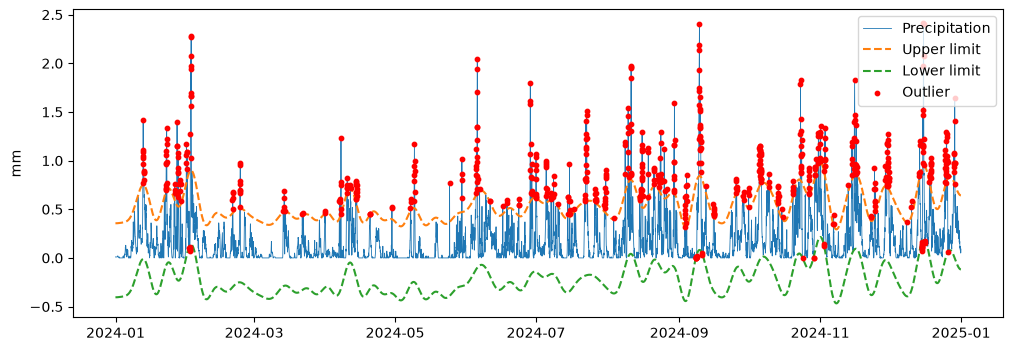

{'n_outliers': 610, 'share': 0.06944444444444445, 'median_satv': np.float32(-0.03186994), 'robust_std': np.float32(0.1267597)}


,precipitation
2024-01-12 20:00:00+00:00,0.77
2024-01-12 21:00:00+00:00,1.03
2024-01-12 22:00:00+00:00,1.05
2024-01-12 23:00:00+00:00,1.42
2024-01-13 00:00:00+00:00,1.11


In [55]:
# SPC test 
fig, summary, out = spc_outliers(weather["precipitation"])
display(fig); print(summary); out.head()

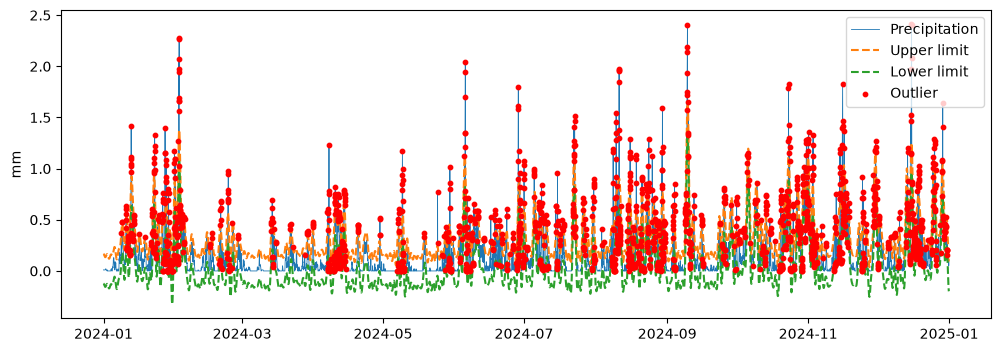

{'n_outliers': 1639, 'share': 0.18658925318761385, 'median_satv': np.float32(-0.005855538), 'robust_std': np.float32(0.07260363)}


In [56]:
# SPC test 2: more low frequencies removed and narrower limits
fig, summary, out = spc_outliers(weather["precipitation"], cutoff=0.05, n_std=2)
display(fig); print(summary)

With the default parameters, 610 hours (6.9 %) are flagged as outliers. This is more than a 3σ limit would give
for normally distributed data. The reason is that precipitation is very skewed: most hours have almost no rain,
so the robust standard deviation is small, and ordinary rain showers end up above the upper limit.
The lower limit is below 0 mm, so all outliers are hours with unusually heavy rain.

### Anomalies in temperature – Local Outlier Factor (LOF)
LOF compares the local density around each point with the density around its nearest neighbours.
Points in much sparser regions than their neighbours get a high LOF score and are marked as anomalies.

In [57]:
# Local Outlier Factor (LOF) anomaly detection
def lof_anomalies(series, contamination=0.01, n_neighbors=20):
    """Temperature anomalies using Local Outlier Factor. contamination = expected share of outliers."""
    t = np.arange(len(series))                                      
    X = StandardScaler().fit_transform(np.column_stack([t, series.to_numpy()]))
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    is_out = lof.fit_predict(X) == -1                              

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(series.index, series, lw=0.6, label="Temperature")
    ax.scatter(series.index[is_out], series[is_out], color="red", s=10, zorder=3, label="Anomaly")
    ax.legend(); ax.set_ylabel("°C")

    summary = {"n_anomalies": int(is_out.sum()), "share": float(is_out.mean()),
               "min": float(series[is_out].min()), "max": float(series[is_out].max())}
    plt.close(fig)
    return fig, summary, series[is_out].to_frame("temperature")

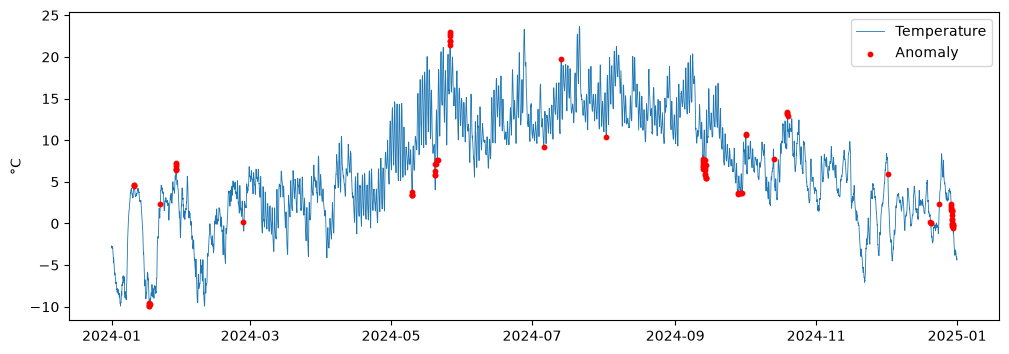

{'n_anomalies': 88, 'share': 0.010018214936247723, 'min': -9.956449508666992, 'max': 22.97854995727539}


,temperature
2024-01-10 17:00:00+00:00,4.56355
2024-01-10 18:00:00+00:00,4.58855
2024-01-10 19:00:00+00:00,4.52355
2024-01-17 07:00:00+00:00,-9.59145
2024-01-17 08:00:00+00:00,-9.80145


In [58]:
# LOF test 
fig, summary, anom = lof_anomalies(weather["temperature_2m"])
display(fig); print(summary); anom.head()

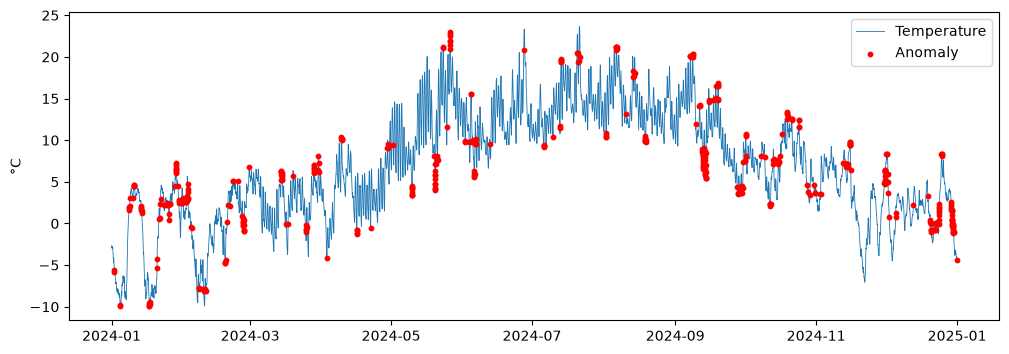

{'n_anomalies': 440, 'share': 0.05009107468123861, 'min': -9.956449508666992, 'max': 22.97854995727539}


In [59]:
# LOF test 2: 5 % outliers
fig, summary, anom = lof_anomalies(weather["temperature_2m"], contamination=0.05)
display(fig); print(summary)

### STL decomposition of the filling level
STL splits a time series into trend + seasonal + residual.
The data is the weekly filling level from Magasinstatistikk for NO3 (1995 – today), so the period is 52 weeks.


In [60]:
# STL decomposition of weekly filling level
def stl_plot(series, period=52, seasonal=13, trend=89, robust=True):
    """STL decomposition of weekly filling level. seasonal and trend must be odd integers."""
    s = series.asfreq("W-SUN").interpolate()
    res = STL(s, period=period, seasonal=seasonal, trend=trend, robust=robust).fit()
    fig = res.plot()
    fig.set_size_inches(12, 8)
    plt.close(fig)        
    return fig

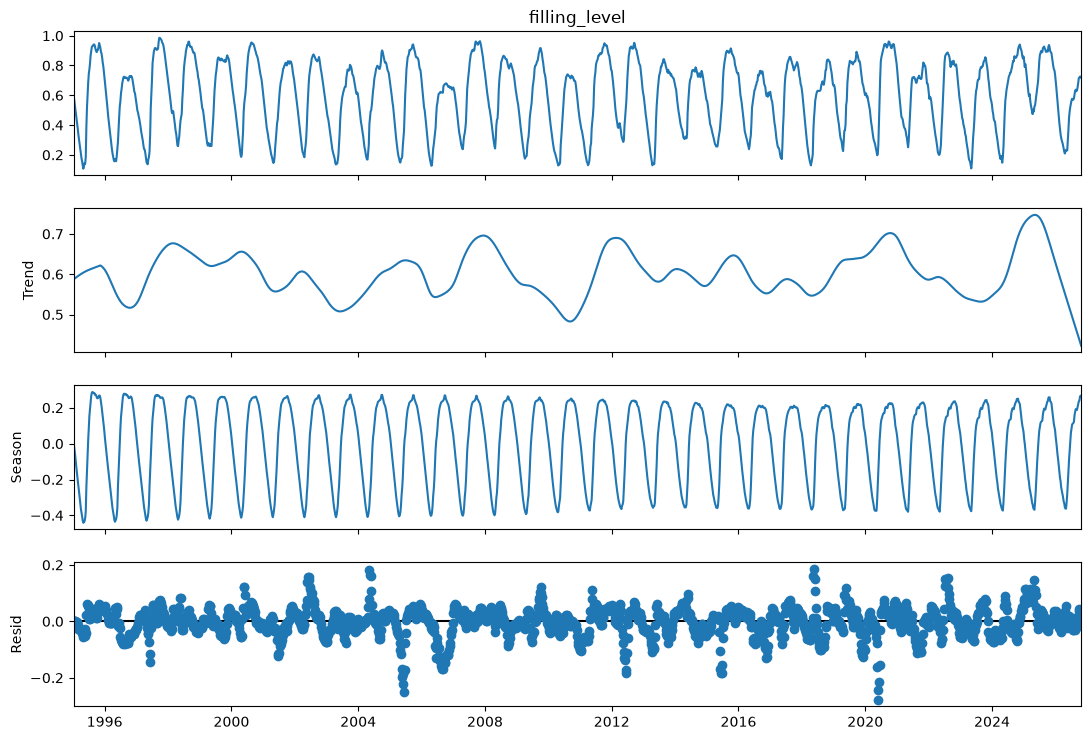

In [61]:
df = fetch_reservoirs()
fill = select_area(df, "EL", 3)["filling_level"]
stl_plot(fill)

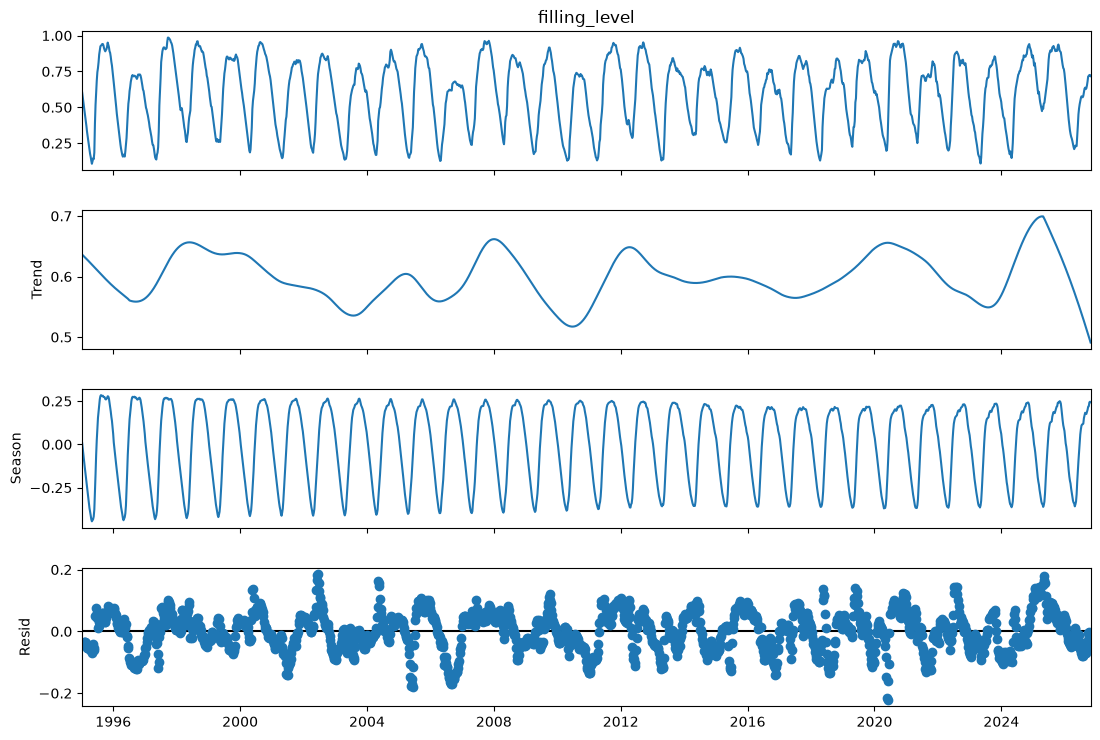

In [62]:
# STL test 2: longer trend smoother and non-robust fit
# -> smoother trend, and unusual weeks now affect trend and season instead of ending up in the residual
stl_plot(fill, trend=157, robust=False)

### Spectrogram of the filling level
A spectrogram splits the series into overlapping windows and computes the frequency content of each window,
so it shows which periodicities are present and how they change over time.


In [63]:
# Spectrogram of weekly data
def spectrogram_plot(series, window_length=104, overlap=78):
    """Spectrogram of weekly data. window_length and overlap are in weeks."""
    s = series.asfreq("W-SUN").interpolate()
    f, t, Sxx = spectrogram(s.to_numpy(), fs=52,          
                            nperseg=window_length, noverlap=overlap, detrend="linear")
    times = s.index[0] + pd.to_timedelta(t * 365.25, unit="D")   

    fig, ax = plt.subplots(figsize=(12, 4))
    m = ax.pcolormesh(times, f, 10 * np.log10(Sxx + 1e-12), shading="auto")
    fig.colorbar(m, ax=ax, label="Power (dB)")
    ax.set_ylabel("Cycles per year"); ax.set_xlabel("Time")
    plt.close(fig)
    return fig


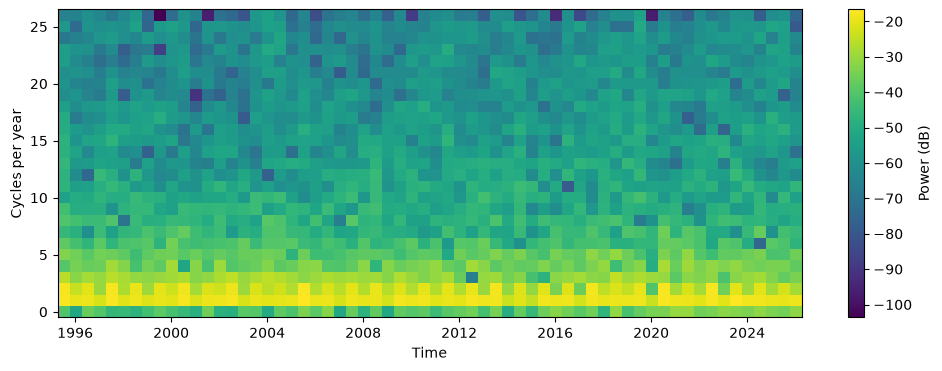

In [64]:
# Spectrogram test
spectrogram_plot(fill, window_length=52, overlap=26)

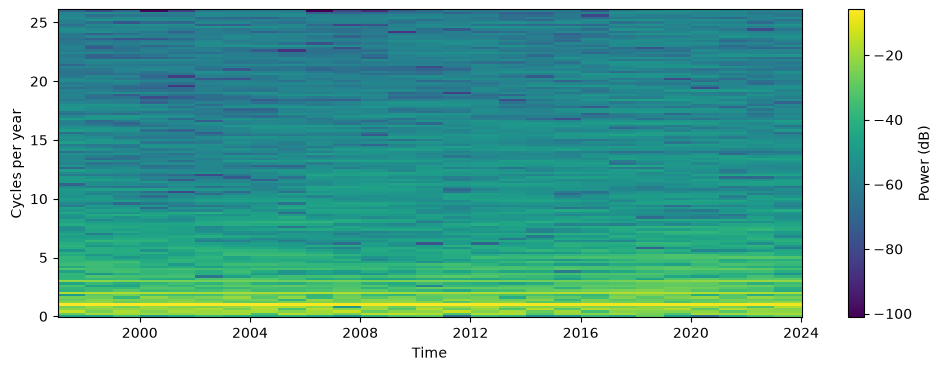

In [65]:
# Spectrogram test 2: long window and high overlap
# -> sharp frequency resolution, but changes over time are smoothed out
spectrogram_plot(fill, window_length=260, overlap=208)